In [53]:
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("..")


from trips.test_problems.Tomography import Tomography
import astra

import jlinops


from rsolvers import RIASGKS, RMMGKS

In [2]:
tomo = Tomography()

settings


In [3]:
nx = 100
ny = 100
ground_truth, _, _ = tomo.gen_true("grains", nx=100, ny=100)

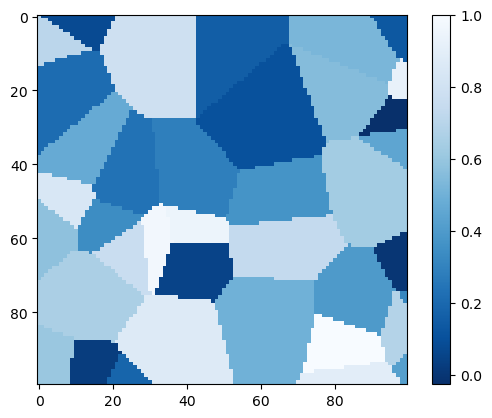

In [4]:
plt.imshow(ground_truth.reshape((nx,ny)), cmap="Blues_r")
plt.colorbar()
plt.show()

In [67]:
n_views = 4
noise_stdev = 0.1
noise_var = noise_stdev**2
#noise_level = 0.1

A, btrue, _, _, _ = tomo.gen_data(ground_truth, nx, ny, 10)
#bnoisy, delta = tomo.add_noise(btrue, "Gaussian", noise_level=noise_level)
bnoisy = (A @ ground_truth) + noise_stdv


# delta is the noise standard deviation

no crime


In [70]:
# Define an object of the class Tomogrpahy
Tomo = Tomography ()
# Specify the dimensions of the phantom and the number of angels
nx = 256
ny = 256
views = 50
# Define the true solution throught the function gen_true ().
( x_true , nx , ny ) = Tomo . gen_true ( testproblem = "tectonic", nx = nx , ny = ny
)
# Define the forward operator
A = Tomo . forward_Op ( nx , ny , views )
# Generate the data
(A , b_true , p , q , AforMatrixOperation ) = Tomo . gen_data ( x_true , nx , ny ,
views )
# Add noise in the true simulated sinogram b_true
(b , delta ) = Tomo . add_noise ( b_true = b_true , opt = "Gaussian", noise_level
= 0.001)

SyntaxError: invalid character '’' (U+2019) (992157503.py, line 8)

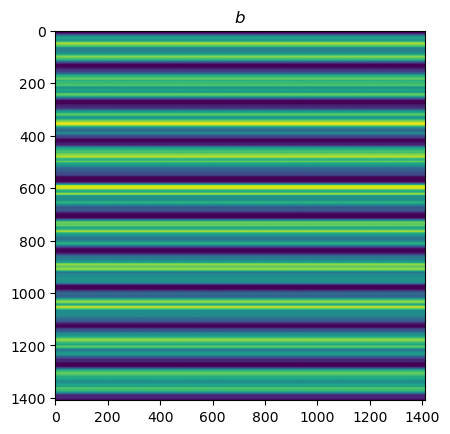

In [68]:
plt.imshow(bnoisy)
plt.title("$b$")
plt.show()

In [69]:
plt.imshow( (A.T @ bnoisy.flatten()).reshape((nx,ny)) )
plt.title("$A^T b$")
plt.show()

ValueError: dimension mismatch

# Solve problem

In [64]:
L = jlinops.Neumann2D((nx, ny)) # gradient regularization
#L = jlinops.IdentityOperator((M*N, M*N)) # identity regularization

rmmgks_solver = RMMGKS(A, L, bnoisy.flatten(), noise_var=delta**2)
data = rmmgks_solver.solve(n_iter=200, init_dim=10, kmin=10, kmax=25, hyperpr_r=1.0, hyperpr_beta=1.5 + 1e-3, x_true=ground_truth.flatten(), regparam="dp3", eta=1.5)

UnboundLocalError: cannot access local variable 'data' where it is not associated with a value

In [6]:
A.shape

(564, 10000)

In [7]:
A.T.shape

(10000, 564)

In [8]:
b.shape

(564,)

In [10]:
4*141

564

In [12]:
b.shape

(564,)

In [13]:
A.T @ b[:,None]

ValueError: dimension mismatch: (10000, 564), (141, 4)